In [15]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
import seaborn as sns
import os
os.chdir("E:/Vishal_Adesh/CDAC/Machine Learning/Datasets")
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [7]:
df = pd.read_csv("nutrient.csv", index_col=0)
df.head()

,energy,protein,fat,calcium,iron
Food_Item,,,,,
BEEF BRAISED,340,20,28,9,2.6
HAMBURGER,245,21,17,9,2.7
BEEF ROAST,420,15,39,7,2.0
BEEF STEAK,375,19,32,9,2.6
BEEF CANNED,180,22,10,17,3.7


In [8]:
df.info()

<class 'pandas.DataFrame'>
Index: 27 entries, BEEF BRAISED to SHRIMP CANNED
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   energy   27 non-null     int64  
 1   protein  27 non-null     int64  
 2   fat      27 non-null     int64  
 3   calcium  27 non-null     int64  
 4   iron     27 non-null     float64
dtypes: float64(1), int64(4)
memory usage: 1.3+ KB


In [13]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
scaler = StandardScaler().set_output(transform='pandas')
scl_df = scaler.fit_transform(df)
scl_df.head()

,energy,protein,fat,calcium,iron
Food_Item,,,,,
BEEF BRAISED,1.335059,0.239681,1.314297,-0.456581,0.152385
HAMBURGER,0.378515,0.479361,0.318516,-0.456581,0.222121
BEEF ROAST,2.140569,-0.958723,2.310078,-0.482699,-0.266028
BEEF STEAK,1.687470,0.000000,1.676399,-0.456581,0.152385
BEEF CANNED,-0.275962,0.719042,-0.315163,-0.352109,0.919476


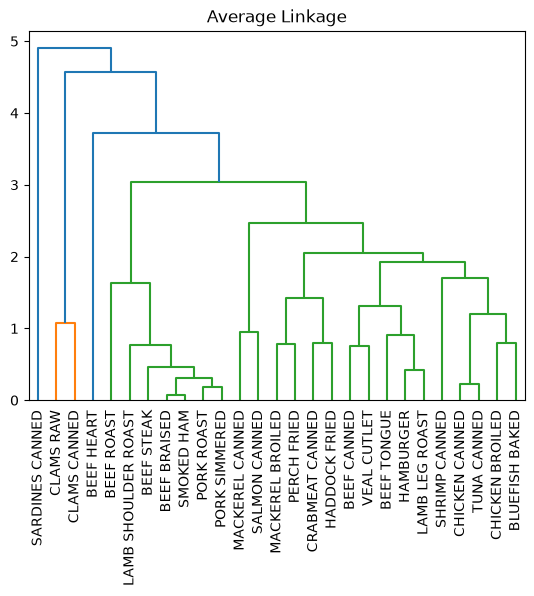

In [10]:
dendrogram(linkage(scl_df, method="average"),labels=( scl_df.index))
plt.title("Average Linkage")
plt.xticks(rotation=90)
plt.show()

In [11]:
clusters = [2,3,4,5,6,7]
scores = []
for i in clusters:
    hc = AgglomerativeClustering(n_clusters=i)
    hc.fit(scl_df)
    scores.append([i, silhouette_score(scl_df, hc.labels_)])
df_scores = pd.DataFrame(scores, columns=["clusters","score"])
df_scores.sort_values(by="score",ascending=False)

,clusters,score
2,4,0.415801
1,3,0.403730
3,5,0.371724
4,6,0.359013
5,7,0.334073
0,2,0.325786


In [14]:
hc = AgglomerativeClustering(n_clusters=4)
hc.fit(scl_df)
hc.labels_

array([1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 2, 2, 0, 0, 0, 0,
       0, 0, 3, 0, 0])

In [16]:
pca = PCA().set_output(transform='pandas')
pca_data = pca.fit_transform(scl_df)
pca_data.head()

,pca0,pca1,pca2,pca3,pca4
Food_Item,,,,,
BEEF BRAISED,1.894907,0.318029,-0.003579,0.327156,0.005915
HAMBURGER,0.659812,-0.079563,-0.512841,0.166202,-0.002632
BEEF ROAST,2.936755,1.122724,1.097788,-0.226335,0.003483
BEEF STEAK,2.321069,0.585663,0.239173,0.318095,0.028400
BEEF CANNED,-0.256477,0.054382,-1.168707,0.474857,-0.042641


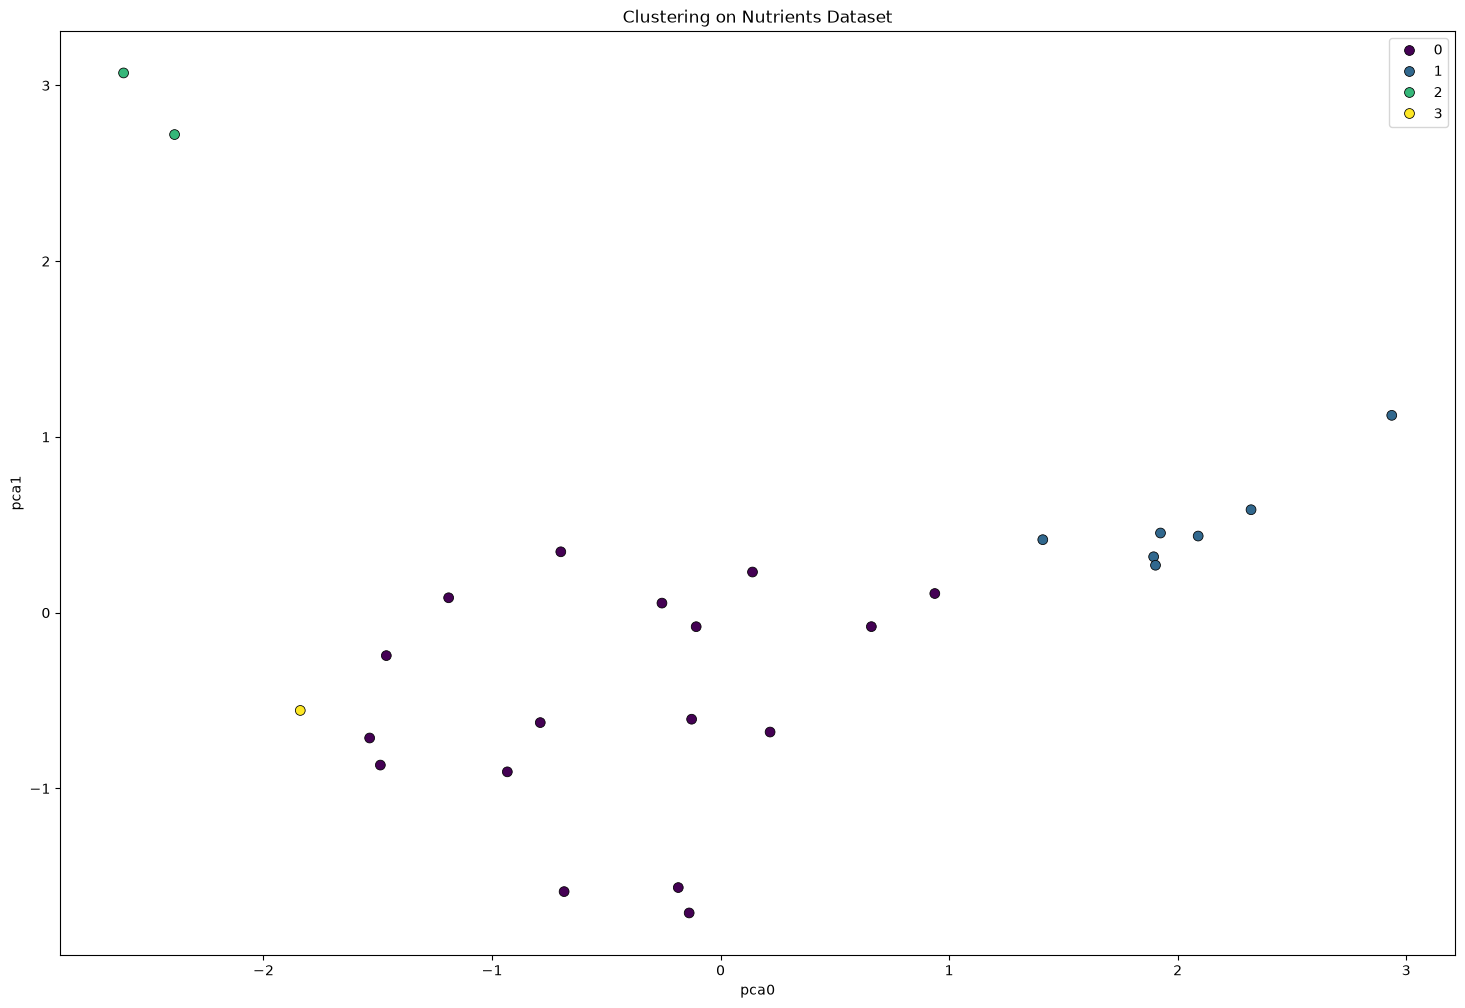

In [22]:
plt.figure(figsize=(18,12))
sns.scatterplot(data = pca_data, x="pca0", y="pca1",hue=hc.labels_,palette='viridis',s=50, edgecolor='k')
plt.title("Clustering on Nutrients Dataset")
# for i in range(len(df)):
#     plt.text(pca_data["pca0"].iloc[i],pca_data["pca1"].iloc[i],df.index[i], fontsize=8)
plt.show()

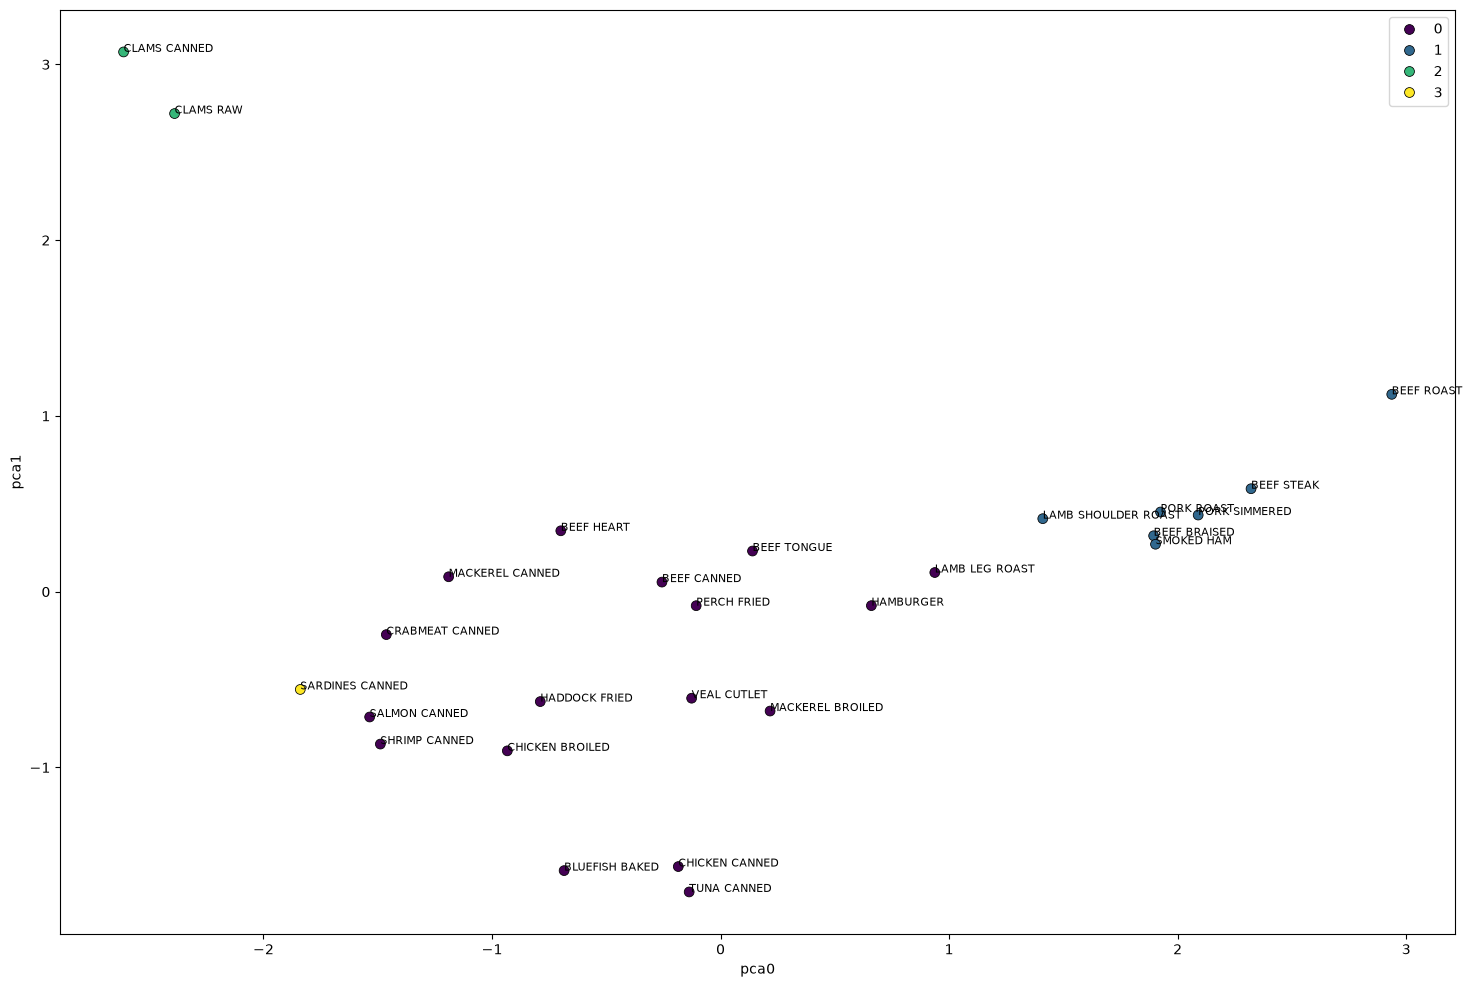

In [21]:
plt.figure(figsize=(18,12))
sns.scatterplot(data = pca_data, x="pca0", y="pca1",hue=hc.labels_,palette='viridis',s=50, edgecolor='k')
for i in range(len(df)):
    plt.text(pca_data["pca0"].iloc[i],pca_data["pca1"].iloc[i],df.index[i], fontsize=8)
plt.show()